# Oráculo por consumidor — `oracle_output.png` (Seção 4.2.4)

Mesmo gráfico de `graphic/oracle/grafico_destino_oracle.ipynb`. Os números vêm das colunas *Oracle form* e *Oracle consumer* de `../data/tabela_de_codigos_artefatos.csv`: barras por forma do oráculo, empilhadas por consumidor. Consumidores sem nenhum estudo não aparecem na legenda.

In [1]:
import sys
sys.path.insert(0, "../scripts")   # graficos/scripts: dados_artefatos.py, paleta_grupos.py

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import dados_artefatos as da
from paleta_grupos import tons_grupo, CINZA_OUTROS, CINZA_INDEFINIDO

# família laranja do grupo oracle: quatro tons do claro ao escuro; "Undefined" em cinza
_t = tons_grupo("oracle", 4, inicio=0.08)
# consumidores do oráculo: chave -> (rótulo da legenda, cor, hachura), na ordem de empilhamento
# os dois tipos determinísticos têm a mesma cor; mutation engine se distingue pela hachura
consumidores = {
    "runner":     ("Deterministic: compiler / test runner", _t[1], None),
    "mutation":   ("Deterministic: mutation engine",        _t[1], "//"),
    "referencia": ("Reference comparison (no execution)",   _t[0], None),
    "classif":    ("Classification / filtering pipeline",   _t[2], None),
    "indefinido": ("Undefined",                             CINZA_OUTROS, None),
    "llm":        ("Another LLM",                           _t[3], None),
}
_codigo = {"runner": "OC1", "mutation": "OC2", "referencia": "OC3", "classif": "OC4", "indefinido": "OC5", "llm": "OC6"}

In [2]:
# Estudos por forma do oráculo, separados por consumidor
rotulos = {"OF1": "Assertions in\ntest body", "OF2": "Expected result / criterion\nin natural language",
           "OF3": "Decides on\nexisting output", "OF4": "Metamorphic\nrelation"}
tabela = da.cruzamento("Oracle form", "Oracle consumer")
ordem = sorted(rotulos, key=lambda c: -tabela.loc[c].sum())      # barras em ordem decrescente
dados = [{"tipo": rotulos[c], "segmentos": {k: int(tabela.loc[c, cod]) for k, cod in _codigo.items()}} for c in ordem]

x_pos = range(len(dados))
totais_cons = {k: sum(d["segmentos"].get(k, 0) for d in dados) for k in consumidores}
total = sum(totais_cons.values())
print(totais_cons, "total =", total)
assert total == len(da.estudos("Oracle form"))

{'runner': 63, 'mutation': 0, 'referencia': 2, 'classif': 7, 'indefinido': 16, 'llm': 2} total = 90


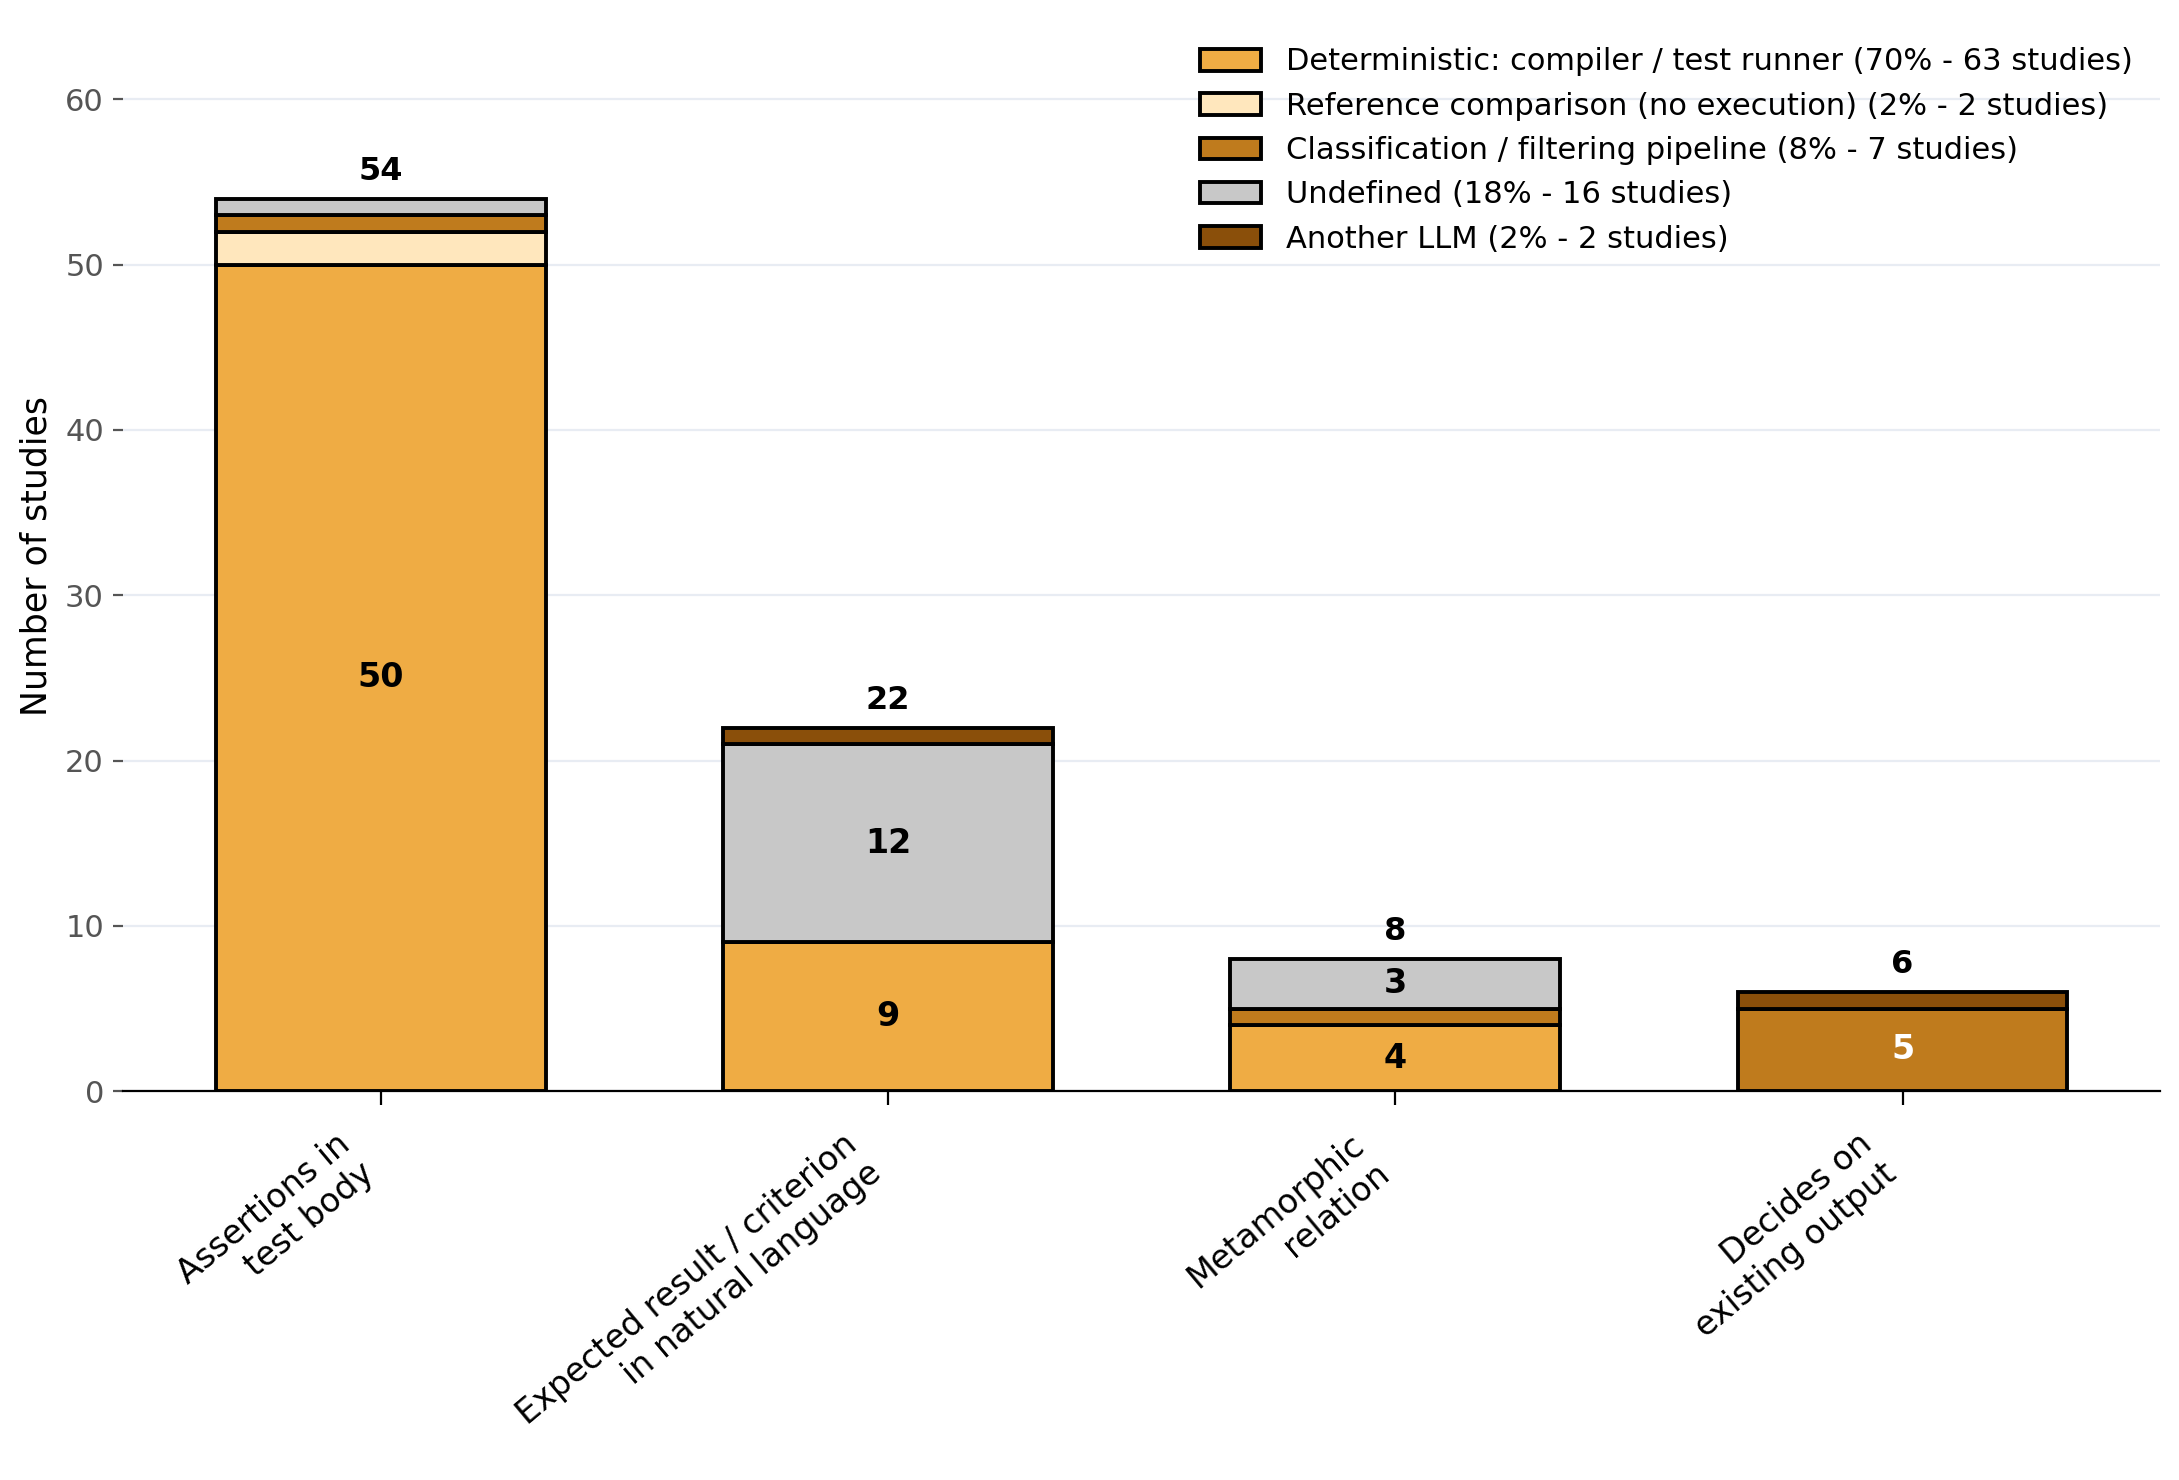

In [3]:
def cor_texto_legivel(hex_cor):
    r, g, b = (int(hex_cor[i : i + 2], 16) for i in (1, 3, 5))
    luminancia = 0.299 * r + 0.587 * g + 0.114 * b
    return "black" if luminancia > 150 else "white"

fig, ax = plt.subplots(figsize=(11, 7.5), dpi=200)

for x, d in zip(x_pos, dados):
    base = 0
    for chave in consumidores:            # empilha sempre na ordem da legenda
        v = d["segmentos"].get(chave, 0)
        if v == 0:
            continue
        _, cor, hachura = consumidores[chave]
        ax.bar(x, v, bottom=base, color=cor, hatch=hachura, width=0.65,
               edgecolor="black", linewidth=1.4, zorder=3)
        # número dentro do segmento só quando cabe
        if v >= 3:
            ax.text(x, base + v / 2, str(v), ha="center", va="center", fontsize=12,
                    fontweight="bold", color=cor_texto_legivel(cor), zorder=4,
                    bbox=dict(facecolor=cor, edgecolor="none", pad=1) if hachura else None)
        base += v
    ax.text(x, base + 0.7, str(base), ha="center", va="bottom", fontsize=11.5,
            fontweight="bold", color="black")

ax.set_xticks(list(x_pos))
ax.set_xticklabels([d["tipo"] for d in dados], rotation=40, ha="right", fontsize=12)

ax.set_ylim(0, max(sum(d["segmentos"].values()) for d in dados) * 1.2)
ax.set_ylabel("Number of studies", fontsize=12.5)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("black")
ax.tick_params(axis="x", length=5, pad=8, color="black")
ax.tick_params(axis="y", colors="#555555", labelsize=11)
ax.yaxis.grid(True, color="#e8ecf3", zorder=0)
ax.set_axisbelow(True)

legend_handles = [
    Patch(facecolor=cor, hatch=hachura, edgecolor="black", linewidth=1.4,
          label=f"{nome} ({totais_cons[k] / total:.0%} - {totais_cons[k]} studies)")
    for k, (nome, cor, hachura) in consumidores.items() if totais_cons[k] > 0
]
ax.legend(handles=legend_handles, loc="upper right", frameon=False, fontsize=11)

plt.tight_layout()
plt.savefig("oracle_output.png", bbox_inches="tight", dpi=200)
plt.savefig("oracle_output.pdf", bbox_inches="tight")
plt.show()